# ClusterBP v2: leakage-free re-evaluation

The notebook rebuilds the dataset from the raw export (`2025_04_15/`) and evaluates the models without leakage.
Old notebooks, `cache/` and `data/` are not used or changed: all intermediate files go to `cache_v2/`, final tables and figures to `results_v2/`.

**What changed compared with `h0.ipynb` and why**

| In h0 | Now | Why |
|---|---|---|
| One target: a mix of codes 33901, 33900, 33012, 33601, 33801 | Separate **A** (33012, 33901) and **B** (33601, 33801, 33802, 33911). Code 33902 (heart-rate red zone) and 33810 ("signs of reaching target BP", appears only in some months) are not in the main targets; the earlier code sets are sensitivity checks `A_with33902`, `B_with33810`; the old target **OLD** is kept for comparison with the paper | Events with different clinical meaning |
| Windows use measurement time, events use server time | Everything on the server timeline: the history window contains only what was on the server before the cutoff | Causality |
| The horizon starts right after the cutoff | A 1-day gap for A and a 7-day gap for B | A events are confirmed by a physician within ~5 h of the measurement; a B event is computed from the previous week's measurements, so without a gap it is partly determined by the input window |
| The GRU is trained on a random window split, without early stopping | All models are trained within 5-fold CV with a strict patient-level split; early stopping on inner validation | Leakage between patients |
| Blend weights and thresholds are tuned on the test set | Tuned on inner validation (separate patients from the fold's training part); the test set is untouched | Optimistic estimate |
| GDTW cluster from the patient's whole series, including the future | Cluster templates are built in each fold from the first 30 days of training patients; a window is assigned by its own past 30 days | Leakage from the future |
| Balanced sample (~55% positives) | Evaluation at the real event rate; F1 on a balanced test is reported separately, only for comparison with the paper | Metrics on a balanced sample have no clinical interpretation |
| No simple baselines | Rule "an event already occurred in the last 7 days", maximum SBP of the window, logistic regression | The model must be shown to beat the obvious |
| t-test over 5 folds | Patient-level bootstrap with confidence intervals for all metrics and paired differences | Windows of one patient are correlated |

**Long history.** Features over the 30/60/90 days before the cutoff are added (`LH_COLS`, `long_history_features` in `clusterbp_lib.py`): long-term SBP variability and event counts. They are used in XGB_full, XGB_bp (BP part only) and LR.

**Cache.** Windows and predictions are tagged with a hash of targets and features (`*.meta.json`). If targets or features change, windows are rebuilt and cross-validation is rerun automatically.

In [1]:
import os
import gc
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
import torch

# Constants, target and feature definitions, phenotypes, models and metrics are in clusterbp_lib.py.
# CLUSTERBP_DEBUG=1 — quick run on 1,500 patients with output to cache_v2_debug/ and results_v2_debug/.
from clusterbp_lib import (DEBUG, RAW_DIR, DATA_DIR, CACHE_DIR, RESULTS_DIR, MODELS_DIR, SEED, TARGETS,
                           EVENT_GROUPS, FEATURE_SETS, LR_COLS, LH_COLS, long_history_features, rule_score, cache_is_current, mark_cache, N_FOLDS, N_CLUSTERS, HISTORY_DAYS, STRIDE_DAYS,
                           MIN_HIST_MEAS, MAX_POINTS, FOLLOWUP_DAYS, PHENO_DAYS, fold_masks, fit_phenotypes,
                           assign_phenotypes, set_phenotype_columns, fit_xgb, train_gru, gru_logits, sigmoid,
                           best_threshold, tune_blend, apply_blend, boot_eval, ci, balanced_f1)

warnings.filterwarnings('ignore')
torch.set_num_threads(os.cpu_count())
N_BOOT = 1000
print('DEBUG =', DEBUG)

DEBUG = False


## 1. Loading and cleaning the raw data

Cleaning as in the paper: duplicates (patient, measurement time), physiological bounds SBP ∈ [40; 250], DBP ∈ [30; 150], HR ∈ [30; 220].
Time is converted to days (float) on the server clock.

In [2]:
def to_days(s):
    return pd.to_datetime(s, errors='coerce').values.astype('datetime64[s]').astype('int64') / 86400.0


def parse_int(s):
    return pd.to_numeric(s.astype(str).str.replace(r'\s', '', regex=True), errors='coerce')


def load_raw():
    paths = {k: os.path.join(DATA_DIR, f'{k}.parquet') for k in ['measurements', 'patients', 'events']}
    if all(os.path.exists(p) for p in paths.values()):
        return [pd.read_parquet(paths[k]) for k in ['measurements', 'patients', 'events']]

    cols = {'время измерения': 't_meas', 'время сохранения на сервере': 't', 'САД': 'sbp', 'ДАД': 'dbp',
            'ЧП': 'hr', 'id пациента': 'pid', 'дата рождения пациента': 'birth', 'рост': 'height', 'масса': 'weight'}
    m = pd.read_csv(os.path.join(RAW_DIR, 'Первичные данные от 10.04.2025.csv'),
                    usecols=list(cols), low_memory=False).rename(columns=cols)
    stats = {'raw': len(m)}
    for c in ['sbp', 'dbp', 'hr', 'height', 'weight', 'pid']:
        m[c] = pd.to_numeric(m[c], errors='coerce')
    m['td'] = to_days(m['t'])
    m = m.dropna(subset=['td', 'pid', 'sbp', 'dbp', 'hr'])
    n = len(m)
    m = m.drop_duplicates(subset=['pid', 't_meas'])
    stats['duplicates'] = n - len(m)
    ok = m.sbp.between(40, 250) & m.dbp.between(30, 150) & m.hr.between(30, 220)
    stats['implausible'] = int((~ok).sum())
    m = m[ok]

    pats = m.groupby('pid').agg(birth=('birth', 'first'), height=('height', 'max'), weight=('weight', 'max'))
    pats['birth_days'] = to_days(pats['birth'])
    pats['bmi'] = pats['weight'] / (pats['height'] / 100) ** 2
    pats.loc[~pats['bmi'].between(12, 60), 'bmi'] = np.nan
    grp = pd.read_csv(os.path.join(RAW_DIR, 'МО и Пациенты 10.04.2025.csv'), sep=';')
    grp['pid'] = parse_int(grp['id пациента'])
    # A patient may have several programmes: take one with a defined arm, if any
    grp = grp.dropna(subset=['pid'])
    grp = grp.assign(defined=grp['группа наблюдения'] != 'undefined').sort_values('defined', ascending=False)
    grp = grp.drop_duplicates('pid').set_index('pid')['группа наблюдения']
    pats['group'] = grp.reindex(pats.index).fillna('undefined').values
    pats = pats[['birth_days', 'bmi', 'group']].reset_index()

    m = m[['pid', 'td', 'sbp', 'dbp', 'hr']].sort_values(['pid', 'td']).reset_index(drop=True)
    m['pid'] = m['pid'].astype('int64')
    for c in ['sbp', 'dbp', 'hr']:
        m[c] = m[c].astype('float32')

    ev = pd.read_csv(os.path.join(RAW_DIR, 'Клинически значимые события от 15.04.2025.csv'))
    ev.columns = ['prog', 'pid', 'ts', 'code']
    ev['td'] = to_days(ev['ts'])
    ev = ev.dropna(subset=['td', 'pid'])[['pid', 'td', 'code']]
    ev['pid'] = ev['pid'].astype('int64')

    m.to_parquet(paths['measurements'])
    pats.to_parquet(paths['patients'])
    ev.to_parquet(paths['events'])
    json.dump(stats, open(os.path.join(DATA_DIR, 'cleaning_stats.json'), 'w'))
    return m, pats, ev


meas, pats, events = load_raw()
print('Programme arm in the cohort:', pats['group'].value_counts().to_dict(),
      '— if almost all are "undefined", set USE_ARM_FEATURES = False in clusterbp_lib.py')
if os.path.exists(os.path.join(DATA_DIR, 'cleaning_stats.json')):
    print('Cleaning:', json.load(open(os.path.join(DATA_DIR, 'cleaning_stats.json'))))
if DEBUG:
    rng = np.random.default_rng(SEED)
    keep = rng.choice(meas.pid.unique(), 1500, replace=False)
    meas = meas[meas.pid.isin(keep)].reset_index(drop=True)
print(f'Measurements: {len(meas):,}, patients: {meas.pid.nunique():,}, events: {len(events):,}')

Programme arm in the cohort: {'undefined': 583} — if almost all are "undefined", set USE_ARM_FEATURES = False in clusterbp_lib.py
Measurements: 133,337, patients: 583, events: 15,483


## 2. Windows, features and targets

The cutoff `t` is midnight on the server clock, with a 3-day stride. History: measurements saved on the server in `[t − 14, t)`.
Target: whether an event of the given type occurs in `[t + gap, t + gap + 7)`.
For each window we store:
- tabular features (SBP/DBP/HR statistics, slope, ARV variability, shares of readings above thresholds, event history, age, BMI, programme arm);
- the sequence of the last 20 measurements for the GRU (SBP, DBP, HR, days to the cutoff, log hours since the previous measurement);
- daily mean SBP over the past 30 days for phenotype assignment.

In [3]:
def prefix(x):
    return np.concatenate([[0.0], np.cumsum(x, dtype=np.float64)])


def build_windows(meas, pats, events):
    paths = [os.path.join(DATA_DIR, f) for f in ['windows.parquet', 'X_seq.npy', 'seq_len.npy',
                                                   'pheno_win.npy', 'pheno_first.npy', 'pheno_first_pid.npy']]
    if not DEBUG and all(os.path.exists(p) for p in paths) and cache_is_current('windows', DATA_DIR):
        return (pd.read_parquet(paths[0]), np.load(paths[1]), np.load(paths[2]),
                np.load(paths[3]), np.load(paths[4]), np.load(paths[5]))

    ev_sorted = events.sort_values(['pid', 'td'])
    ev_by_group = {}
    for g, codes in EVENT_GROUPS.items():
        e = ev_sorted if codes is None else ev_sorted[ev_sorted.code.isin(codes)]
        ev_by_group[g] = {pid: grp.values for pid, grp in e.groupby('pid')['td']}
    empty = np.array([], dtype=np.float64)
    pat_static = pats.set_index('pid')

    pid_arr = meas['pid'].values
    bounds = np.flatnonzero(np.diff(pid_arr)) + 1
    starts = np.concatenate([[0], bounds])
    ends = np.concatenate([bounds, [len(pid_arr)]])
    TD, S, D, H = (meas[c].values.astype(np.float64) for c in ['td', 'sbp', 'dbp', 'hr'])

    rows, seqs, lens, pwin, pfirst, pfirst_pid = [], [], [], [], [], []
    t0 = time.time()
    for a, b in zip(starts, ends):
        pid = int(pid_arr[a])
        td, s, d, h = TD[a:b], S[a:b], D[a:b], H[a:b]
        day = np.floor(td)
        first_day, last_day = day[0], day[-1]

        ud, inv = np.unique(day, return_inverse=True)
        daymean = np.bincount(inv, weights=s) / np.bincount(inv)
        off = (ud - first_day).astype(int)
        if (off < PHENO_DAYS).any():
            prof = np.full(PHENO_DAYS, np.nan, dtype=np.float32)
            prof[off[off < PHENO_DAYS]] = daymean[off < PHENO_DAYS]
            pfirst.append(prof)
            pfirst_pid.append(pid)

        cut = np.arange(first_day + HISTORY_DAYS, last_day - FOLLOWUP_DAYS + 1 + 1e-9, STRIDE_DAYS)
        if len(cut) == 0:
            continue
        lo = np.searchsorted(td, cut - HISTORY_DAYS)
        hi = np.searchsorted(td, cut)
        n = hi - lo
        ok = n >= MIN_HIST_MEAS
        if not ok.any():
            continue
        cut, lo, hi, n = cut[ok], lo[ok], hi[ok], n[ok]

        u = td - first_day
        pp = s - d
        f = {'pid': np.full(len(cut), pid), 'cut': cut}
        for name, x in [('sbp', s), ('dbp', d), ('hr', h), ('pp', pp)]:
            P, P2 = prefix(x), prefix(x * x)
            mean = (P[hi] - P[lo]) / n
            var = np.maximum((P2[hi] - P2[lo]) / n - mean ** 2, 0) * n / np.maximum(n - 1, 1)
            f[f'{name}_mean'] = mean
            f[f'{name}_std'] = np.sqrt(var)
            if name == 'pp':
                continue
            f[f'{name}_last'] = x[hi - 1]
            Pu, Puu, Pux = prefix(u), prefix(u * u), prefix(u * x)
            su, suu, sux, sx = Pu[hi] - Pu[lo], Puu[hi] - Puu[lo], Pux[hi] - Pux[lo], P[hi] - P[lo]
            den = n * suu - su ** 2
            f[f'{name}_slope'] = np.where(den > 1e-9, (n * sux - su * sx) / np.where(den > 1e-9, den, 1), np.nan)
            PA = prefix(np.concatenate([[0.0], np.abs(np.diff(x))]))
            f[f'{name}_arv'] = (PA[hi] - PA[lo + 1]) / np.maximum(n - 1, 1)
        for name, x in [('tir140', s >= 140), ('frac160', s >= 160), ('frac180', s >= 180), ('dbp_frac90', d >= 90)]:
            P = prefix(x.astype(float))
            f[name] = (P[hi] - P[lo]) / n
        P = prefix(s)
        lo3 = np.searchsorted(td, cut - 3)
        with np.errstate(invalid='ignore', divide='ignore'):
            f['sbp_last3d_minus_prev'] = (P[hi] - P[lo3]) / (hi - lo3) - (P[lo3] - P[lo]) / (lo3 - lo)
        f['sbp_last3d_minus_prev'] = np.where((hi > lo3) & (lo3 > lo), f['sbp_last3d_minus_prev'], np.nan)
        newday = prefix(np.concatenate([[0.0], (np.diff(day) > 0).astype(float)]))
        f['n_meas'] = n
        f['n_days'] = 1 + newday[hi] - newday[lo + 1]
        f['days_since_last_meas'] = cut - td[hi - 1]
        f['days_in_program'] = cut - first_day
        st = pat_static.loc[pid]
        f['age'] = (cut - st['birth_days']) / 365.25
        f['bmi'] = np.full(len(cut), st['bmi'])
        f['grp_experience'] = np.full(len(cut), float(st['group'] == 'experience'))
        f['grp_control'] = np.full(len(cut), float(str(st['group']).startswith('control')))
        mn = np.empty(len(cut)); mx = np.empty(len(cut))
        dmn = np.empty(len(cut)); dmx = np.empty(len(cut))
        hmn = np.empty(len(cut)); hmx = np.empty(len(cut))
        seq = np.zeros((len(cut), MAX_POINTS, 5), dtype=np.float32)
        pw = np.full((len(cut), PHENO_DAYS), np.nan, dtype=np.float32)
        gap_h = np.log1p(np.concatenate([[0.0], np.diff(td) * 24]))
        for i in range(len(cut)):
            sl = slice(lo[i], hi[i])
            mn[i], mx[i] = s[sl].min(), s[sl].max()
            dmn[i], dmx[i] = d[sl].min(), d[sl].max()
            hmn[i], hmx[i] = h[sl].min(), h[sl].max()
            k = min(n[i], MAX_POINTS)
            q = slice(hi[i] - k, hi[i])
            seq[i, MAX_POINTS - k:, 0] = s[q]
            seq[i, MAX_POINTS - k:, 1] = d[q]
            seq[i, MAX_POINTS - k:, 2] = h[q]
            seq[i, MAX_POINTS - k:, 3] = cut[i] - td[q]
            seq[i, MAX_POINTS - k:, 4] = gap_h[q]
            if hi[i] - k == 0:
                seq[i, MAX_POINTS - k, 4] = 0
            j0, j1 = np.searchsorted(ud, cut[i] - PHENO_DAYS), np.searchsorted(ud, cut[i])
            pw[i, (ud[j0:j1] - (cut[i] - PHENO_DAYS)).astype(int)] = daymean[j0:j1]
        f.update(sbp_min=mn, sbp_max=mx, dbp_min=dmn, dbp_max=dmx, hr_min=hmn, hr_max=hmx)

        for g in EVENT_GROUPS:
            e = ev_by_group[g].get(pid, empty)
            i_cut = np.searchsorted(e, cut)
            f[f'ev_{g}_14'] = i_cut - np.searchsorted(e, cut - 14)
            f[f'ev_{g}_7'] = i_cut - np.searchsorted(e, cut - 7)
            last = np.where(i_cut > 0, e[np.maximum(i_cut - 1, 0)] if len(e) else 0, np.nan)
            f[f'ev_{g}_days_since'] = np.where(i_cut > 0, cut - last, np.nan)
        for name, cfg in TARGETS.items():
            e = ev_by_group[name].get(pid, empty)
            a0 = cut + cfg['gap']
            f[f'y_{name}'] = (np.searchsorted(e, a0 + cfg['horizon']) - np.searchsorted(e, a0) > 0).astype(np.int8)

        rows.append(pd.DataFrame(f))
        seqs.append(seq)
        lens.append(np.minimum(n, MAX_POINTS).astype(np.int8))
        pwin.append(pw)
    print(f'Windows built in {time.time() - t0:.0f} s')

    win = pd.concat(rows, ignore_index=True)
    t1 = time.time()
    win = pd.concat([win, long_history_features(win, meas, events)], axis=1)   # features over 30–90 days
    print(f'Long-history features: {len(LH_COLS)}, computed in {time.time() - t1:.0f} s')
    X_seq = np.concatenate(seqs)
    seq_len = np.concatenate(lens)
    pheno_win = np.concatenate(pwin)
    pheno_first = np.stack(pfirst)
    pheno_first_pid = np.array(pfirst_pid)
    if not DEBUG:
        win.to_parquet(paths[0])
        for p, arr in zip(paths[1:], [X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid]):
            np.save(p, arr)
        mark_cache('windows', DATA_DIR)
    return win, X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid


win, X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid = build_windows(meas, pats, events)
print(f'Windows: {len(win):,}, patients: {win.pid.nunique():,}')
summary = pd.DataFrame({
    'share of positive windows': {n: win[f'y_{n}'].mean() for n in TARGETS},
    'patients with ≥1 positive window': {n: win.groupby('pid')[f'y_{n}'].max().sum() for n in TARGETS},
})
summary

Windows: 40,631, patients: 583


,share of positive windows,patients with ≥1 positive window
A,0.133888,421
B,0.047476,315
OLD,0.139303,431


## 3. GDTW phenotypes without leakage

In each fold:
1. we take training patients whose first 30 days of follow-up are covered by measurements (day 0 and a day ≥ 25 present, at least 15 days with data);
2. their z-normalised daily mean SBP series are clustered with GDTW (γ = 1, 14-day window) + Ward, k = 3, as in the paper;
3. the cluster template is the median z-profile;
4. each window is assigned to the nearest template by its own **past** 30 days (1-NN by GDTW).

Time in GDTW is counted from the start of the series, not by calendar: the old implementation counted from a common minimum date, so series of different patients were compared by calendar date.
Clusters are ordered by the mean SBP variability of their members: cluster 0 is the most variable.
Implementation: `fit_phenotypes` and `assign_phenotypes` in `clusterbp_lib.py`.

## 4. Models

- **Rules:** `rule_persist` — number of events of the same type in the last 7 days; `rule_maxSBP` — maximum SBP of the window (minimum SBP for hypotension in VitalDB).
- **LR:** logistic regression on the full feature set.
- **XGB_paper6:** XGBoost on the 6 features of the paper (mean SBP, SD SBP, TIR, age, BMI, cluster); **XGB_bp:** all BP features without event history; **XGB_full:** plus event history.
- **GRU:** GRU(64) + additive attention over the last 20 measurements (as described in the paper), early stopping on AUPRC on inner validation. Negative windows are subsampled to 3:1 for training; probabilities are then corrected to the real event rate.
- **Blends:** `Blend_simple` (w = 0.5), `Blend_global` (w and threshold tuned on validation) and `ClusterBP` (w and threshold per cluster), in two variants: with XGB_paper6, as in the paper, and with XGB_full (`*_full`).

Each model's threshold is tuned on inner validation by Macro F1 (as in the paper) and then applied to the test set.
Models, threshold and blend-weight tuning are implemented in `clusterbp_lib.py`.

## 5. Cross-validation

5 patient-level folds (the same for all targets). Within the training part of a fold, 20% of patients form the inner validation set used for early stopping and tuning of thresholds and blend weights. Test patients are used only for the final predictions.

In [4]:
patients = win['pid'].values
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.full(len(win), -1)
for k, (_, te) in enumerate(sgkf.split(win, win['y_A'], groups=patients)):
    folds[te] = k
win['fold'] = folds

oof = {name: {} for name in TARGETS}          # test predictions: model -> (score, pred)
fold_metrics, blend_params, cluster_info, gru_logs = [], [], [], []
t_all = time.time()

# If cross-validation is already done, load the predictions from the cache
OOF_PATH = os.path.join(CACHE_DIR, 'oof_predictions.parquet')
RESUME = not DEBUG and os.path.exists(OOF_PATH) and os.path.exists(os.path.join(RESULTS_DIR, 'fold_metrics.csv')) \
         and cache_is_current('cv')
if not RESUME:   # bootstrap from earlier targets or features is recomputed
    for fname in os.listdir(CACHE_DIR):
        if fname.startswith('bootstrap_') and fname.endswith('.npy'):
            os.remove(os.path.join(CACHE_DIR, fname))
if RESUME:
    oof_df = pd.read_parquet(OOF_PATH)
    for col in oof_df.columns:
        if col.endswith('__score'):
            name, model_name, _ = col.split('__')
            oof[name][model_name] = (oof_df[col].values, oof_df[f'{name}__{model_name}__pred'].values)
    fold_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'fold_metrics.csv')).to_dict('records')
    blend_params = pd.read_csv(os.path.join(RESULTS_DIR, 'clusterbp_params.csv')).to_dict('records')
    cluster_info = pd.read_csv(os.path.join(RESULTS_DIR, 'clusters.csv')).to_dict('records')
    print('Cross-validation loaded from cache')

for k in ([] if RESUME else range(N_FOLDS)):
    t_fold = time.time()
    tr, va, te = fold_masks(win, k)
    train_pids = np.unique(patients[~te])

    templates, sizes, vol = fit_phenotypes(pheno_first, pheno_first_pid, train_pids, SEED + k)
    cl, dist = assign_phenotypes(pheno_win, templates)
    set_phenotype_columns(win, cl, dist)
    np.save(os.path.join(MODELS_DIR, f'templates_fold{k}.npy'), templates)
    for c in range(N_CLUSTERS):
        row = {'fold': k, 'cluster': c, 'n_clustered_patients': int(sizes[c]), 'volatility': vol[c],
               'share_train_windows': float((cl[tr] == c).mean())}
        for name in TARGETS:
            row[f'event_rate_{name}'] = float(win.loc[tr & (cl == c), f'y_{name}'].mean())
        cluster_info.append(row)

    for name, cfg in TARGETS.items():
        y = win[f'y_{name}'].values
        ytr, yva, yte = y[tr], y[va], y[te]
        res = {}

        res['rule_persist'] = (win[f'ev_{name}_7'].values.astype(float), None)
        res['rule_maxSBP'] = (rule_score(win, name), None)   # minimum SBP for hypotension in VitalDB

        lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000))
        lr.fit(win.loc[tr, LR_COLS].values, ytr)
        res['LR'] = (lr.predict_proba(win[LR_COLS].values)[:, 1], None)

        xgb_sets = ['full'] if not cfg['full'] else ['paper6', 'bp', 'full']
        for fs in xgb_sets:
            cols = FEATURE_SETS[fs]
            m = fit_xgb(win.loc[tr, cols].values, ytr, win.loc[va, cols].values, yva, SEED + k)
            res[f'XGB_{fs}'] = (m.predict_proba(win[cols].values)[:, 1], None)
            m.save_model(os.path.join(MODELS_DIR, f'xgb_{fs}_{name}_fold{k}.json'))

        if cfg['full']:
            model, mu, sd, corr, log = train_gru(X_seq[tr], seq_len[tr], ytr, X_seq[va], seq_len[va], yva, SEED + k)
            gru_logs.append({'target': name, 'fold': k, 'epochs': len(log), 'val_auprc': log})
            torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd, 'corr': corr},
                       os.path.join(MODELS_DIR, f'gru_{name}_fold{k}.pt'))
            pg = sigmoid(gru_logits(model, X_seq, seq_len, mu, sd) + corr)
            res['GRU'] = (pg, None)
            for suffix, xname in [('', 'XGB_paper6'), ('_full', 'XGB_full')]:
                px = res[xname][0]
                simple = 0.5 * pg + 0.5 * px
                thr, _ = best_threshold(yva, simple[va])
                res[f'Blend_simple{suffix}'] = (simple, (simple > thr).astype(np.int8))
                gp = tune_blend(yva, pg[va], px[va])
                res[f'Blend_global{suffix}'] = apply_blend(pg, px, gp)
                cp = tune_blend(yva, pg[va], px[va], clusters=cl[va])
                res[f'ClusterBP{suffix}'] = apply_blend(pg, px, cp, clusters=cl)
                for key, (w, thr) in cp.items():
                    blend_params.append({'target': name, 'fold': k, 'variant': 'ClusterBP' + suffix,
                                         'cluster': key, 'w_gru': w, 'threshold': thr})

        for model_name, (score, pred) in res.items():
            if pred is None:
                thr, _ = best_threshold(yva, score[va])
                pred = (score > thr).astype(np.int8)
            st = oof[name].setdefault(model_name, (np.full(len(win), np.nan), np.zeros(len(win), np.int8)))
            st[0][te] = score[te]
            st[1][te] = pred[te]
            fold_metrics.append({'target': name, 'fold': k, 'model': model_name,
                                 'auroc': roc_auc_score(yte, score[te]),
                                 'auprc': average_precision_score(yte, score[te]),
                                 'macro_f1': f1_score(yte, pred[te], average='macro')})
    print(f'Fold {k}: {time.time() - t_fold:.0f} s')
    gc.collect()

print(f'Total: {(time.time() - t_all) / 60:.1f} min')
fold_df = pd.DataFrame(fold_metrics)
if not RESUME:
    fold_df.to_csv(os.path.join(RESULTS_DIR, 'fold_metrics.csv'), index=False)
    pd.DataFrame(blend_params).to_csv(os.path.join(RESULTS_DIR, 'clusterbp_params.csv'), index=False)
    pd.DataFrame(cluster_info).to_csv(os.path.join(RESULTS_DIR, 'clusters.csv'), index=False)
    json.dump(gru_logs, open(os.path.join(RESULTS_DIR, 'gru_training.json'), 'w'))

    oof_df = win[['pid', 'cut', 'fold'] + [f'y_{n}' for n in TARGETS]].copy()
    for name in TARGETS:
        for model_name, (score, pred) in oof[name].items():
            oof_df[f'{name}__{model_name}__score'] = score
            oof_df[f'{name}__{model_name}__pred'] = pred
    oof_df.to_parquet(OOF_PATH)
    mark_cache('cv')    # windows, fold models and predictions match the current targets and features

Fold 0: 93 s


Fold 1: 80 s


Fold 2: 82 s


Fold 3: 78 s


Fold 4: 79 s
Total: 6.9 min


## 6. Final metrics with confidence intervals

Predictions of all folds are pooled (out-of-fold). 95% CI: patient-level bootstrap (a patient is resampled with all their windows).
`macro_F1_balanced`: Macro F1 on a test set where negative windows are randomly subsampled to the number of positives, with the threshold tuned on an equally balanced sample of the **other** folds. These are the conditions of the paper (test with ~57% positives), so the column is **only** for comparison with Table 4; it has no clinical meaning.

In [5]:
COMPARISONS = [('ClusterBP', 'Blend_global'), ('ClusterBP', 'Blend_simple'), ('ClusterBP', 'GRU'),
               ('ClusterBP', 'XGB_paper6'), ('ClusterBP_full', 'Blend_global_full'), ('ClusterBP_full', 'XGB_full'),
               ('XGB_full', 'XGB_bp'), ('XGB_full', 'rule_persist'), ('XGB_bp', 'rule_maxSBP'), ('GRU', 'rule_maxSBP')]

all_tables, all_comp = {}, []
rng = np.random.default_rng(SEED)
for name in TARGETS:
    y = oof_df[f'y_{name}'].values.astype(float)
    pid = oof_df['pid'].values
    names = list(oof[name])
    models = [(oof_df[f'{name}__{m}__score'].values, oof_df[f'{name}__{m}__pred'].values.astype(float)) for m in names]
    t0 = time.time()
    boot_path = os.path.join(CACHE_DIR, f'bootstrap_{name}.npy')
    if not DEBUG and os.path.exists(boot_path):
        B = np.load(boot_path)
    else:
        B = boot_eval(y, pid, models)
        if not DEBUG:
            np.save(boot_path, B)
    pos_idx, neg_idx = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    if len(pos_idx) <= len(neg_idx):     # subsample the larger class
        bal = np.sort(np.concatenate([pos_idx, rng.choice(neg_idx, len(pos_idx), replace=False)]))
    else:
        bal = np.sort(np.concatenate([rng.choice(pos_idx, len(neg_idx), replace=False), neg_idx]))
    fold = oof_df['fold'].values
    rows = []
    for j, m in enumerate(names):
        score, pred = models[j]
        fd = fold_df[(fold_df.target == name) & (fold_df.model == m)]
        tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
        fn = ((pred == 0) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
        is_prob = not m.startswith('rule')
        rows.append({
            'model': m,
            'AUROC': roc_auc_score(y, score), 'AUROC 95% CI': ci(B[:, j, 0]),
            'AUPRC': average_precision_score(y, score), 'AUPRC 95% CI': ci(B[:, j, 1]),
            'Brier': brier_score_loss(y, np.clip(score, 0, 1)) if is_prob else np.nan,
            'macro_F1': f1_score(y, pred, average='macro'), 'macro_F1 95% CI': ci(B[:, j, 2]),
            'macro_F1 by fold': f'{fd.macro_f1.mean():.3f} ± {fd.macro_f1.std():.3f}',
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp), 'PPV': tp / max(tp + fp, 1),
            'macro_F1_balanced': '{:.3f} ± {:.3f}'.format(*balanced_f1(y, score, fold, bal)),
        })
    table = pd.DataFrame(rows).set_index('model').sort_values('AUPRC', ascending=False)
    all_tables[name] = table
    table.to_csv(os.path.join(RESULTS_DIR, f'metrics_{name}.csv'))
    for a, b in COMPARISONS:
        if a in names and b in names:
            ia, ib = names.index(a), names.index(b)
            for mi, metric in enumerate(['AUROC', 'AUPRC', 'macro_F1']):
                d = B[:, ia, mi] - B[:, ib, mi]
                point = table.loc[a, metric] - table.loc[b, metric]
                all_comp.append({'target': name, 'comparison': f'{a} − {b}', 'metric': metric,
                                 'delta': point, '95% CI': ci(d),
                                 'p (two-sided)': min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
    print(f'{name}: bootstrap {time.time() - t0:.0f} s')

comp_df = pd.DataFrame(all_comp)
comp_df.to_csv(os.path.join(RESULTS_DIR, 'comparisons.csv'), index=False)

A: bootstrap 17 s


B: bootstrap 17 s


OLD: bootstrap 17 s


In [6]:
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
for name, table in all_tables.items():
    print(f"\n=== {TARGETS[name]['title']} — share of positives {oof_df[f'y_{name}'].mean():.3f} ===")
    display(table.round(3))


=== A: hypotension (MAP < 65) in 5–10 min — share of positives 0.134 ===


,AUROC,AUROC 95% CI,AUPRC,AUPRC 95% CI,Brier,macro_F1,macro_F1 95% CI,macro_F1 by fold,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
Blend_global_full,0.862,[0.845; 0.878],0.567,[0.490; 0.635],0.082,0.725,[0.700; 0.749],0.725 ± 0.021,0.534,0.922,0.515,0.770 ± 0.014
ClusterBP_full,0.861,[0.844; 0.877],0.566,[0.490; 0.633],0.083,0.721,[0.695; 0.745],0.721 ± 0.020,0.526,0.922,0.511,0.773 ± 0.016
XGB_full,0.861,[0.844; 0.877],0.566,[0.491; 0.631],0.083,0.724,[0.699; 0.747],0.725 ± 0.023,0.547,0.917,0.504,0.776 ± 0.016
Blend_simple_full,0.860,[0.843; 0.877],0.565,[0.485; 0.634],0.083,0.724,[0.698; 0.748],0.723 ± 0.018,0.520,0.927,0.522,0.769 ± 0.015
LR,0.854,[0.836; 0.871],0.554,[0.470; 0.624],0.084,0.720,[0.694; 0.743],0.719 ± 0.018,0.535,0.917,0.501,0.772 ± 0.014
XGB_bp,0.855,[0.837; 0.872],0.547,[0.467; 0.616],0.084,0.719,[0.692; 0.744],0.718 ± 0.021,0.508,0.927,0.517,0.766 ± 0.018
GRU,0.847,[0.828; 0.865],0.532,[0.448; 0.605],0.086,0.709,[0.682; 0.734],0.707 ± 0.025,0.501,0.920,0.492,0.762 ± 0.019
Blend_simple,0.840,[0.821; 0.858],0.521,[0.433; 0.597],0.091,0.706,[0.678; 0.733],0.705 ± 0.021,0.476,0.927,0.503,0.756 ± 0.018
ClusterBP,0.832,[0.813; 0.851],0.495,[0.413; 0.571],0.091,0.707,[0.680; 0.733],0.706 ± 0.019,0.510,0.915,0.482,0.752 ± 0.022



=== B: hypertension (SBP ≥ 160) in 5–10 min — share of positives 0.047 ===


,AUROC,AUROC 95% CI,AUPRC,AUPRC 95% CI,Brier,macro_F1,macro_F1 95% CI,macro_F1 by fold,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
Blend_simple_full,0.791,[0.762; 0.816],0.230,[0.178; 0.288],0.041,0.634,[0.602; 0.667],0.618 ± 0.048,0.283,0.970,0.322,0.713 ± 0.030
LR,0.817,[0.794; 0.838],0.228,[0.176; 0.288],0.041,0.632,[0.609; 0.657],0.622 ± 0.032,0.387,0.944,0.257,0.740 ± 0.020
GRU,0.776,[0.748; 0.803],0.223,[0.164; 0.291],0.041,0.627,[0.597; 0.660],0.612 ± 0.047,0.281,0.967,0.296,0.704 ± 0.031
ClusterBP_full,0.785,[0.757; 0.810],0.221,[0.176; 0.266],0.041,0.628,[0.598; 0.659],0.613 ± 0.041,0.285,0.967,0.298,0.709 ± 0.050
Blend_simple,0.781,[0.753; 0.807],0.219,[0.162; 0.279],0.041,0.626,[0.597; 0.657],0.613 ± 0.048,0.289,0.964,0.287,0.703 ± 0.032
Blend_global_full,0.785,[0.757; 0.810],0.213,[0.167; 0.261],0.042,0.635,[0.603; 0.667],0.618 ± 0.048,0.299,0.967,0.308,0.714 ± 0.035
XGB_bp,0.785,[0.755; 0.811],0.212,[0.167; 0.257],0.041,0.632,[0.607; 0.655],0.625 ± 0.025,0.303,0.964,0.295,0.641 ± 0.196
ClusterBP,0.777,[0.749; 0.802],0.198,[0.149; 0.251],0.042,0.624,[0.592; 0.656],0.609 ± 0.049,0.269,0.968,0.295,0.708 ± 0.031
XGB_full,0.777,[0.747; 0.801],0.196,[0.154; 0.240],0.042,0.631,[0.604; 0.660],0.618 ± 0.035,0.323,0.958,0.279,0.708 ± 0.043



=== A without gap — share of positives 0.139 ===


,AUROC,AUROC 95% CI,AUPRC,AUPRC 95% CI,Brier,macro_F1,macro_F1 95% CI,macro_F1 by fold,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
Blend_global_full,0.936,[0.929; 0.943],0.775,[0.735; 0.811],0.058,0.825,[0.810; 0.839],0.825 ± 0.014,0.678,0.957,0.717,0.864 ± 0.012
XGB_full,0.935,[0.928; 0.943],0.775,[0.735; 0.810],0.058,0.825,[0.810; 0.840],0.824 ± 0.013,0.646,0.965,0.752,0.861 ± 0.015
ClusterBP_full,0.936,[0.929; 0.943],0.774,[0.733; 0.810],0.058,0.824,[0.810; 0.838],0.824 ± 0.013,0.680,0.956,0.713,0.865 ± 0.012
Blend_simple_full,0.936,[0.929; 0.943],0.773,[0.733; 0.810],0.059,0.825,[0.811; 0.839],0.825 ± 0.016,0.703,0.950,0.694,0.863 ± 0.015
LR,0.929,[0.921; 0.937],0.764,[0.721; 0.802],0.060,0.822,[0.807; 0.837],0.822 ± 0.010,0.708,0.946,0.681,0.859 ± 0.009
GRU,0.928,[0.920; 0.937],0.745,[0.700; 0.786],0.062,0.817,[0.801; 0.832],0.817 ± 0.017,0.665,0.955,0.704,0.859 ± 0.015
XGB_bp,0.929,[0.922; 0.937],0.745,[0.702; 0.784],0.062,0.819,[0.804; 0.834],0.819 ± 0.017,0.685,0.951,0.692,0.860 ± 0.013
ClusterBP,0.919,[0.911; 0.928],0.718,[0.673; 0.760],0.067,0.814,[0.798; 0.830],0.814 ± 0.019,0.663,0.953,0.696,0.859 ± 0.015
Blend_global,0.921,[0.913; 0.930],0.718,[0.670; 0.761],0.067,0.817,[0.801; 0.832],0.817 ± 0.018,0.676,0.952,0.693,0.860 ± 0.016


In [7]:
display(comp_df[comp_df.metric != 'AUROC'].round(4))

,target,comparison,metric,delta,95% CI,p (two-sided)
1,A,ClusterBP − Blend_global,AUPRC,0.0032,[-0.010; 0.016],0.664
2,A,ClusterBP − Blend_global,macro_F1,-0.0008,[-0.005; 0.004],0.768
4,A,ClusterBP − Blend_simple,AUPRC,-0.0262,[-0.042; -0.009],0.006
5,A,ClusterBP − Blend_simple,macro_F1,0.0012,[-0.005; 0.008],0.696
7,A,ClusterBP − GRU,AUPRC,-0.0375,[-0.057; -0.019],0.000
8,A,ClusterBP − GRU,macro_F1,-0.0016,[-0.007; 0.003],0.524
10,A,ClusterBP − XGB_paper6,AUPRC,0.1838,[0.144; 0.224],0.000
11,A,ClusterBP − XGB_paper6,macro_F1,0.0828,[0.068; 0.099],0.000
13,A,ClusterBP_full − Blend_global_full,AUPRC,-0.0009,[-0.003; 0.001],0.426
14,A,ClusterBP_full − Blend_global_full,macro_F1,-0.0036,[-0.007; -0.001],0.018


## 7. ClusterBP parameters and clusters by fold

Analogue of Table 2 of the paper, but parameters are tuned on each fold's validation set, not on the test set.

In [8]:
bp_df = pd.DataFrame(blend_params)
bp_df = bp_df[bp_df.cluster != 'global']
display(bp_df.groupby(['target', 'variant', 'cluster'])[['w_gru', 'threshold']].agg(['mean', 'std']).round(3))
cl_df = pd.DataFrame(cluster_info)
display(cl_df.groupby('cluster').mean(numeric_only=True).drop(columns='fold').round(3))

w_gru        threshold       
                               mean    std      mean    std
target variant        cluster                              
A      ClusterBP      0        0.50  0.276     0.254  0.067
                      1        0.65  0.418     0.209  0.039
                      2        0.80  0.146     0.250  0.045
       ClusterBP_full 0        0.20  0.177     0.320  0.036
                      1        0.07  0.097     0.279  0.080
                      2        0.12  0.110     0.284  0.038
B      ClusterBP      0        0.56  0.164     0.105  0.030
                      1        0.53  0.333     0.150  0.057
                      2        0.71  0.263     0.182  0.044
       ClusterBP_full 0        0.36  0.204     0.088  0.013
                      1        0.31  0.297     0.159  0.058
                      2        0.41  0.210     0.164  0.039
OLD    ClusterBP      0        0.90  0.094     0.425  0.034
                      1        0.80  0.269     0.336  0.161
                      2        0.68  0.284     0.322  0.066
       ClusterBP_full 0        0.29  0.279     0.366  0.052
                      1        0.25  0.166     0.325  0.096
                      2        0.17  0.233     0.356  0.040

,n_clustered_patients,volatility,share_train_windows,event_rate_A,event_rate_B,event_rate_OLD
cluster,,,,,,
0,184.0,17.959999,0.305,0.151,0.038,0.170
1,126.6,16.531000,0.360,0.116,0.056,0.103
2,153.4,16.100000,0.336,0.138,0.047,0.152


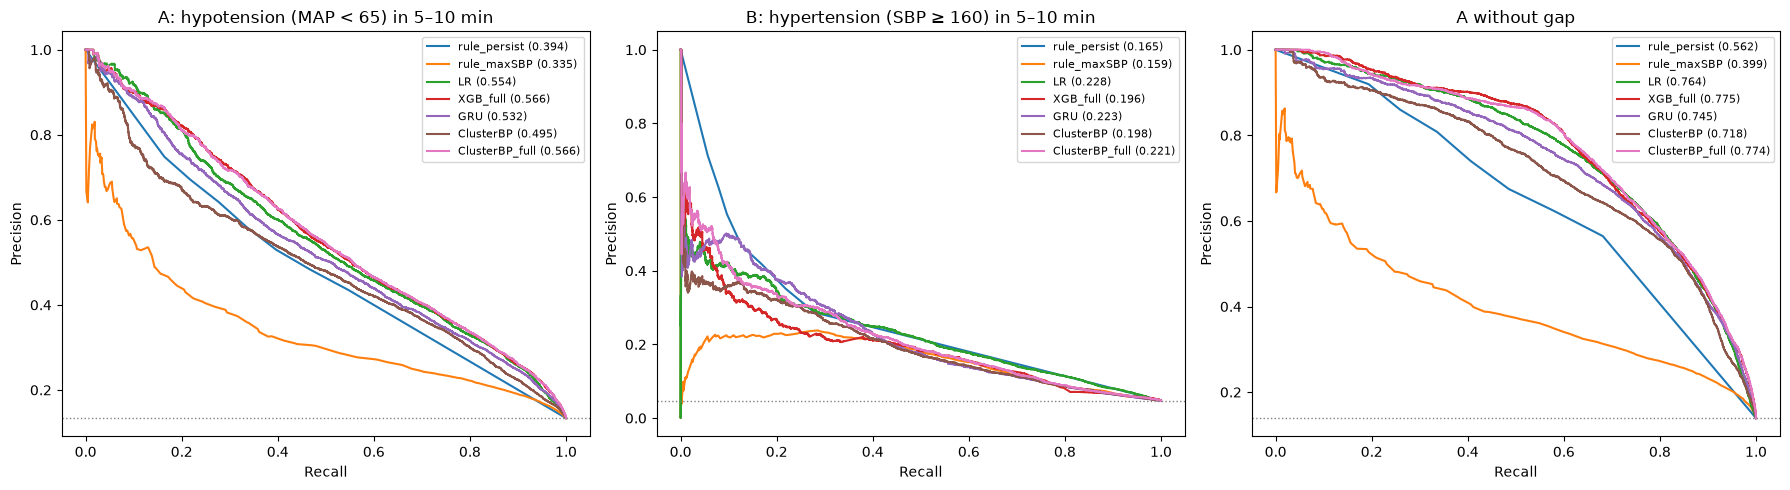

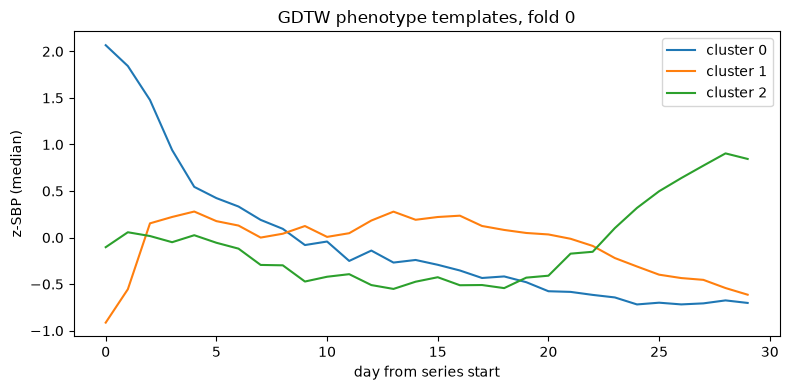

In [9]:
from sklearn.metrics import precision_recall_curve

show = ['rule_persist', 'rule_maxSBP', 'LR', 'XGB_full', 'GRU', 'ClusterBP', 'ClusterBP_full']
full_targets = [n for n, c in TARGETS.items() if c['full']]
fig, axes = plt.subplots(1, len(full_targets), figsize=(6 * len(full_targets), 5))
for ax, name in zip(np.atleast_1d(axes), full_targets):
    y = oof_df[f'y_{name}'].values
    for m in show:
        if m in oof[name]:
            p, r, _ = precision_recall_curve(y, oof_df[f'{name}__{m}__score'].values)
            ax.plot(r, p, label=f"{m} ({all_tables[name].loc[m, 'AUPRC']:.3f})")
    ax.axhline(y.mean(), color='gray', ls=':', lw=1)
    ax.set_title(TARGETS[name]['title'])
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'pr_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
T0 = np.load(os.path.join(MODELS_DIR, 'templates_fold0.npy'))
for c, prof in enumerate(T0):
    ax.plot(np.arange(PHENO_DAYS), prof, label=f'cluster {c}')
ax.set_xlabel('day from series start')
ax.set_ylabel('z-SBP (median)')
ax.set_title('GDTW phenotype templates, fold 0')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'phenotype_templates_fold0.png'), dpi=200, bbox_inches='tight')
plt.show()